<a href="https://colab.research.google.com/github/rithiga504-beep/Machine-Learning-Tutorials/blob/main/Tutorial_7_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Tutorial 7
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = {
    'Study_Hours': [2,3,4,5,6,7,8,2,4,6,3,5,7,8,1,4,6,7,3,5],
    'Attendance': [55,60,65,70,75,80,90,50,68,78,58,72,85,92,45,66,76,88,62,74],
    'Practice_Tests': [1,2,2,3,4,5,6,1,3,4,2,3,5,6,1,2,4,5,2,4],
    'Revision_Hours': [1,2,2,3,4,5,6,1,2,4,2,3,4,6,1,2,4,5,2,3]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df.head())

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

pca = PCA(n_components=2)
reduced_data = pca.fit_transform(scaled_data)

result = pd.DataFrame(reduced_data, columns=['PC1', 'PC2'])

print("\nDataset after PCA:")
print(result.round(2))

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(3))

print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


Original Dataset:
   Study_Hours  Attendance  Practice_Tests  Revision_Hours
0            2          55               1               1
1            3          60               2               2
2            4          65               2               2
3            5          70               3               3
4            6          75               4               4

Dataset after PCA:
     PC1   PC2
0  -2.69 -0.10
1  -1.61  0.10
2  -1.16 -0.28
3  -0.08 -0.08
4   1.00  0.12
5   2.09  0.32
6   3.37  0.28
7  -2.89  0.14
8  -0.73 -0.31
9   1.12 -0.03
10 -1.69  0.19
11 -0.00 -0.18
12  1.96 -0.38
13  3.44  0.18
14 -3.33  0.52
15 -1.12 -0.33
16  1.04  0.07
17  2.40 -0.07
18 -1.53 -0.00
19  0.39 -0.15

Explained Variance Ratio:
[0.978 0.013]

Total Variance Retained:
99.17 %


In [7]:
#Tutorial 8

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

df = pd.DataFrame({
    'Study_Hours': [1,2,1,3,2,4,3,5,4,6,2,5,6,7,3,7,8,6,4,8,2,5,3,6,1,7,4,8,2,5],
    'Attendance': [40,50,45,55,48,60,58,70,65,80,52,72,85,90,57,88,95,82,62,96,45,68,55,78,42,92,63,98,49,75],
    'Practice_Tests': [0,1,0,1,1,2,1,3,2,4,1,3,4,5,2,5,6,4,2,6,0,2,1,4,0,6,2,5,1,3],
    'Result': ['Fail','Pass','Fail','Pass','Fail','Fail','Pass','Pass','Fail','Pass',
               'Pass','Fail','Pass','Pass','Fail','Fail','Pass','Pass','Pass','Fail',
               'Fail','Pass','Fail','Pass','Pass','Pass','Fail','Pass','Fail','Fail']
})

X = df[['Study_Hours', 'Attendance', 'Practice_Tests']]
y = df['Result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = GaussianNB()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred) * 100, 2), "%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, pred, labels=['Fail', 'Pass']))

student = pd.DataFrame([[3, 55, 1]], columns=X.columns)
print("\nPredicted Result:", model.predict(student)[0])




Accuracy: 66.67 %

Confusion Matrix:
 [[3 1]
 [2 3]]

Predicted Result: Fail


Linear SVM
Accuracy: 100.0 %
Confusion Matrix:
 [[25  0]
 [ 0 25]]
Support Vectors: [11 10]

Nonlinear SVM (RBF)
Accuracy: 100.0 %
Confusion Matrix:
 [[25  0]
 [ 0 25]]
Support Vectors: [11  9]



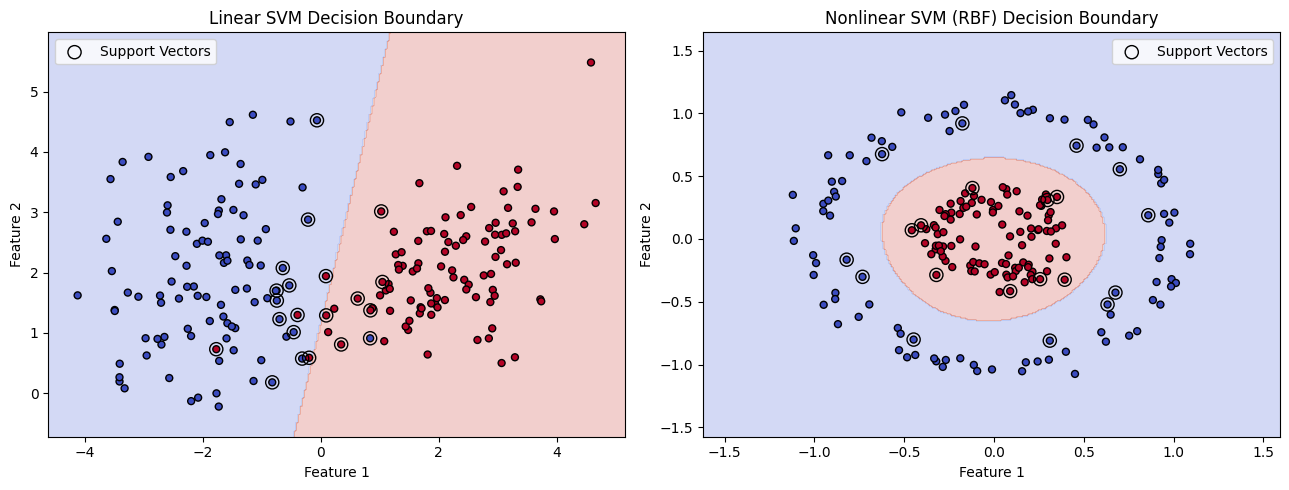

In [8]:
# Tutorial 9

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

X1, y1 = make_classification(
    n_samples=200, n_features=2, n_redundant=0,
    n_informative=2, n_clusters_per_class=1,
    class_sep=2.0, random_state=42
)

X2, y2 = make_circles(
    n_samples=200, factor=0.3, noise=0.08,
    random_state=42
)

datasets = [
    ("Linear SVM", X1, y1, "linear"),
    ("Nonlinear SVM (RBF)", X2, y2, "rbf")
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, X, y, kernel) in zip(axes, datasets):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = SVC(kernel=kernel, C=1.0, gamma="scale")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Support Vectors:", model.n_support_)
    print()

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(scaler.transform(grid)).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",
               edgecolors="black", s=25)

    support_vectors = scaler.inverse_transform(model.support_vectors_)
    ax.scatter(
        support_vectors[:, 0], support_vectors[:, 1],
        s=90, facecolors="none", edgecolors="black",
        label="Support Vectors"
    )

    ax.set_title(name + " Decision Boundary")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()

plt.tight_layout()
plt.show()
